# Costes y comparación de políticas

Respondemos a la pregunta 5. Valoramos el VM, la permanencia, los transfers y los costes de los escenarios; distinguimos CVP, contribución y oportunidad perdida. Comparamos políticas con la misma demanda y conservamos el plan base de los documentos.

Requiere [Escenarios producción y simulación](03_escenarios_produccion_y_simulacion.ipynb).

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

proyecto = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'src/rutas.py').is_file() and (p / 'data').is_dir()), None)
if proyecto is None:
    raise FileNotFoundError('Abre Jupyter desde la carpeta de entrega o desde notebooks.')
if str(proyecto) not in sys.path:
    sys.path.insert(0, str(proyecto))
from src.rutas import DATOS, RESULTADOS, leer_csv
assert DATOS.parent == proyecto, 'Los datos deben pertenecer a esta copia de entrega.'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                    'axes.spines.right': False, 'font.size': 11, 'axes.titlesize': 13})
print('Datos originales: data/. Resultados: resultados/.')


Datos originales: data/. Resultados: resultados/.


<a id="costes"></a>

## A Costes y margen

**Objetivo:** poner euros al flujo físico del [Simulación mensual](03_escenarios_produccion_y_simulacion.ipynb#simulacion), sin mezclar costes de la marca, oportunidades perdidas y caja de los concesionarios. Al terminar tendremos la tabla 5 del caso para el total y los siete segmentos.

Los precios y márgenes proceden de `segmentos.csv`, los shocks del bloque de escenarios y las cantidades/edades del bloque de simulación. No estamos calculando beneficio neto: faltan costes fijos e impuestos sobre beneficios. Fuente: enunciado, apartados 2.2–2.6, 7.5 y tabla 5 (enunciado original del caso).

### 1. Qué entra en cada cuenta

El **beneficio bruto** por coche ya descuenta fabricación, transporte, aduana base y margen contractual del concesionario. Volver a restarlos duplicaría los costes. A ese bruto se le resta VM para obtener CVP después de gasto comercial.

Para comparar el plan también restamos permanencia de la marca, transfers, arancel adicional y CO₂, y sumamos el ahorro de cambio. Llamaremos al resultado **contribución de la marca**. El CVP después de VM y esta contribución se guardan en columnas distintas.

$$C = bruto - VM - permanencia - transfers - arancel - CO_2 + ahorro.$$

| Partida | Tratamiento |
|---|---|
| Ventas perdidas | Oportunidad no ganada, informativa. No se resta de nuevo del margen realizado. |
| Intereses de la red | Coste del concesionario independiente, separado de contribución de marca. |
| Principal a 180 días | Necesidad de caja de la red, sin considerarlo un gasto adicional de marca. |
| Producción del trimestre final | Llega en A014. Su margen se realizará al vender; no se cuenta como venta A013. |
| Stock inicial | Coche ya importado en A012. No vuelve a cargar arancel adicional/ahorro de importación. |
| CO₂ | Se aplica a todo retail A013, incluida la venta del stock inicial. |

El arancel adicional se aproxima con un porcentaje del PFF, no con una base aduanera real. Se imputa al vender las llegadas nuevas y los transfers. El ahorro de cambio usa la misma base. Para transfers extranjeros mantenemos el proxy del bloque de escenarios: no conocemos su contrato ni origen exacto. La sensibilidad a aplicar estas partidas a todo retail se muestra en el bloque de políticas.

In [2]:
from src.costes import ejecutar_costes, cargar_trayectorias
config, tablas, economicos = ejecutar_costes()
salida = RESULTADOS/'07_costes_margen'
display(pd.Series(config, name='Hipótesis económica'))
display(tablas['parametros_vm'][['segmento','beneficio_bruto_marca_eur','vm_real_0_90_eur','vm_real_91_180_eur','vm_real_mas_180_eur','vm_mas_180_imputado']])

coste_marca_eur_dia                                                      2.0
tipo_credito_0_90                                                       0.01
tipo_credito_91_180                                                     0.05
dias_anio_financiero                                                     365
transfer_fraccion_bruto                                                  0.2
csuv_vm_mas_180_factor                                                   1.2
base_arancel_cambio                                       nuevas_y_transfers
nota                       CSUV >180: 120% de su VM 91-180, hipótesis. Ar...
Name: Hipótesis económica, dtype: object

,segmento,beneficio_bruto_marca_eur,vm_real_0_90_eur,vm_real_91_180_eur,vm_real_mas_180_eur,vm_mas_180_imputado
0,B,1842.0,1717.0,1745.0,1583.0,False
1,C,3672.0,2305.0,2572.0,3064.0,False
2,MD,7561.0,3517.0,3701.0,3964.0,False
3,SSUV,4833.0,1976.0,2024.0,1978.0,False
4,CSUV,6174.0,2370.0,2470.0,2964.0,True
5,MSUV,7782.0,1895.0,2090.0,2422.0,False
6,S,6841.0,1887.0,2143.0,2411.0,False


### 2. VM por edad y el dato que falta

Para cada venta usamos el VM histórico del segmento y de su edad. Las ventas por transfer se consideran frescas. Esta es una hipótesis de gasto futuro, no una tarifa garantizada.

En CSUV no hay VM observado para más de 180 días. La base usa **1,20 × VM de 91–180 días**, es decir, 2.964 €/coche. Es una imputación conservadora para ensayar el riesgo, no un dato. El bloque de políticas compara también factores 1,00 y 1,50.

El VM histórico de B y SSUV no sube siempre con la edad. Respetamos el dato y permitimos que el exceso frente a VM fresco sea negativo. No imponemos una relación que los CSV no muestran.

In [3]:
t5 = tablas['tabla_5']
display(t5[['escenario','segmento','ventas_mas_180','ventas_csuv_vm_imputado','vm_eur','vm_tarifa_eur','cvp_despues_vm_eur','contribucion_marca_eur']].sort_values(['escenario','segmento']))

,escenario,segmento,ventas_mas_180,ventas_csuv_vm_imputado,vm_eur,vm_tarifa_eur,cvp_despues_vm_eur,contribucion_marca_eur
0,Central,B,0.000,0.000,2.669522e+06,3.690435e+06,1.939072e+05,7.383635e+04
1,Central,C,402.259,0.000,8.996869e+06,5.756774e+06,4.141025e+06,3.575810e+06
2,Central,CSUV,768.876,768.876,6.018646e+06,6.729051e+06,8.179974e+06,7.601009e+06
3,Central,MD,77.076,0.000,2.637941e+06,1.994041e+06,2.933730e+06,2.856122e+06
4,Central,MSUV,35.000,0.000,1.354520e+07,1.253814e+07,4.186184e+07,4.114965e+07
5,Central,S,13.905,0.000,1.279395e+06,1.418808e+06,3.187271e+06,3.032438e+06
6,Central,SSUV,0.000,0.000,1.143721e+07,8.710201e+06,1.653383e+07,1.589109e+07
7,Central,TOTAL,1297.116,768.876,4.658478e+07,4.083745e+07,7.703157e+07,7.417995e+07
8,Optimista,B,0.000,0.000,3.117872e+06,4.310878e+06,2.269621e+05,3.509806e+05
9,Optimista,C,288.492,0.000,1.048700e+07,6.854358e+06,5.155763e+06,5.229279e+06


### 3. Permanencia y financiación

La marca paga 2 €/día por coche sin vender hasta 180 días. Los días-coche del bloque de simulación ya recortan correctamente cada tramo y solo incluyen tiempo de A013.

$$Coste_{marca}=2(días	ext{-}coche_{0–90}+días	ext{-}coche_{91–180}).$$

La red paga 1% anual sobre PFF en el primer tramo y 5% en el segundo, con año financiero supuesto de 365 días. Usamos las tasas del texto, que generan cifras ligeramente distintas a las columnas diarias redondeadas del CSV.

Un MSUV vendido a los 60 días cuesta 120 € de permanencia a la marca y unos 42,31 € de intereses a la red. Los coches de A012 mayores de 180 días no vuelven a generar vencimiento ni días financiados. Un vencimiento nuevo multiplica el número de coches por el precio de compra del concesionario. No conocemos su caja completa ni repartimos el resultado entre 64 concesionarios sin datos individuales.

In [4]:
f = leer_csv('segmentos.csv').set_index('segmento')
msuv = f.loc['MSUV']
display(pd.Series({'bruto':msuv.beneficio_bruto_marca_eur,'VM fresco':msuv.vm_real_0_90_eur,
    'permanencia 60 días marca':2*60,'interés red 60 días':msuv.pff_medio*.01*60/365,
    'contribución local a 60 días sin shocks':msuv.beneficio_bruto_marca_eur-msuv.vm_real_0_90_eur-120,
    'coste adicional de un transfer':.20*msuv.beneficio_bruto_marca_eur}))
display(t5.query('segmento == "TOTAL"')[['escenario','coste_stock_marca_eur','intereses_concesionarios_eur','principal_vencido_nuevo_eur']])

bruto                                      7782.000000
VM fresco                                  1895.000000
permanencia 60 días marca                   120.000000
interés red 60 días                          42.309041
contribución local a 60 días sin shocks    5767.000000
coste adicional de un transfer             1556.400000
dtype: float64

,escenario,coste_stock_marca_eur,intereses_concesionarios_eur,principal_vencido_nuevo_eur
7,Central,2344870.44,1.383130e+06,2.652085e+07
15,Optimista,2216388.84,1.226300e+06,1.647912e+07
23,Pesimista,2308251.87,1.450272e+06,3.336500e+07


### 4. El coste de quedarse corto

El transfer resta el **20% del bruto base**. El VM se aplica una sola vez. Las unidades perdidas no generan bruto ni VM. Su oportunidad se aproxima por el margen de una venta local fresca con los costes del escenario, limitada a cero cuando esa venta sería deficitaria.

Este cálculo supone que hubiera existido un coche disponible y no reconstruye un coste completo contrafactual de producir más. Sirve para comparar órdenes de magnitud, no para afirmar un beneficio garantizado recuperable.

El dato «ventas perdidas y transfers, en coches y euros» de la tabla 5 se entrega en cuatro columnas separadas para mantener clara esta distinción.

In [5]:
display(t5.query('segmento == "TOTAL"')[['escenario','ventas_perdidas','oportunidad_ventas_perdidas_eur','transfers','coste_transfers_eur']])

,escenario,ventas_perdidas,oportunidad_ventas_perdidas_eur,transfers,coste_transfers_eur
7,Central,529.720,1.648489e+06,449.121,5.067493e+05
15,Optimista,1707.465,5.566371e+06,1518.731,1.645209e+06
23,Pesimista,1024.035,3.349939e+05,0.000,0.000000e+00


### 5. Resultados anuales y riesgo

Sumamos los doce meses de cada réplica y después calculamos cuantiles. Para el total, sumamos segmentos dentro de cada réplica antes de calcular P05 y P95. Sumar los cuantiles de segmentos daría un intervalo incorrecto.

P05–P95 contiene el 90% central de las réplicas de este modelo bajo cada historia. No es un intervalo que garantice el resultado futuro. El error Monte Carlo de la media mide precisión numérica de la simulación; no mide incertidumbre del modelo ni justifica sus hipótesis.

,escenario,media,p05,p50,p95,error_montecarlo_media,fraccion_replicas_negativas
122,Central,7.417995e+07,6.565930e+07,7.407420e+07,8.330445e+07,170648.758562,0.000
258,Optimista,1.012852e+08,9.064339e+07,1.011663e+08,1.125000e+08,212480.326718,0.000
394,Pesimista,-4.080989e+06,-5.943919e+06,-4.232764e+06,-2.055283e+06,37859.726997,0.998


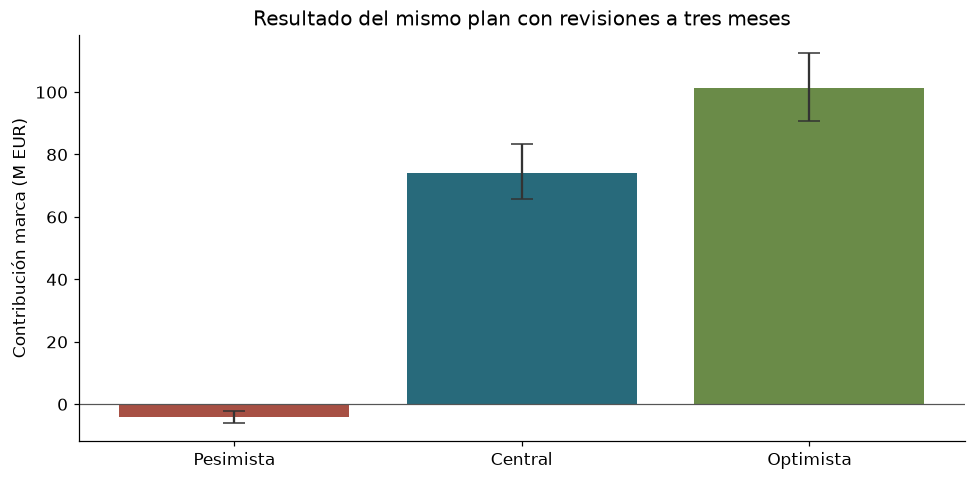

In [6]:
r = tablas['resumen_economico']
display(r.query('segmento == "TOTAL" and metrica == "contribucion_marca_eur"')[['escenario','media','p05','p50','p95','error_montecarlo_media','fraccion_replicas_negativas']])
fig, ax=plt.subplots(figsize=(9,4.5))
orden=['Pesimista','Central','Optimista']
z=r.query('segmento == "TOTAL" and metrica == "contribucion_marca_eur"').set_index('escenario').loc[orden]
ax.bar(orden,z.media/1e6,color=['#A75044','#286A7B','#6A8B48'])
ax.errorbar(orden,z.media/1e6,yerr=np.vstack([(z.media-z.p05)/1e6,(z.p95-z.media)/1e6]),fmt='none',color='#333333',capsize=7)
ax.axhline(0,color='#555555',lw=.8); ax.set_ylabel('Contribución marca (M EUR)')
ax.set_title('Resultado del mismo plan con revisiones a tres meses')
fig.tight_layout(); fig.savefig(salida/'contribucion_escenarios.png',dpi=180); plt.show()

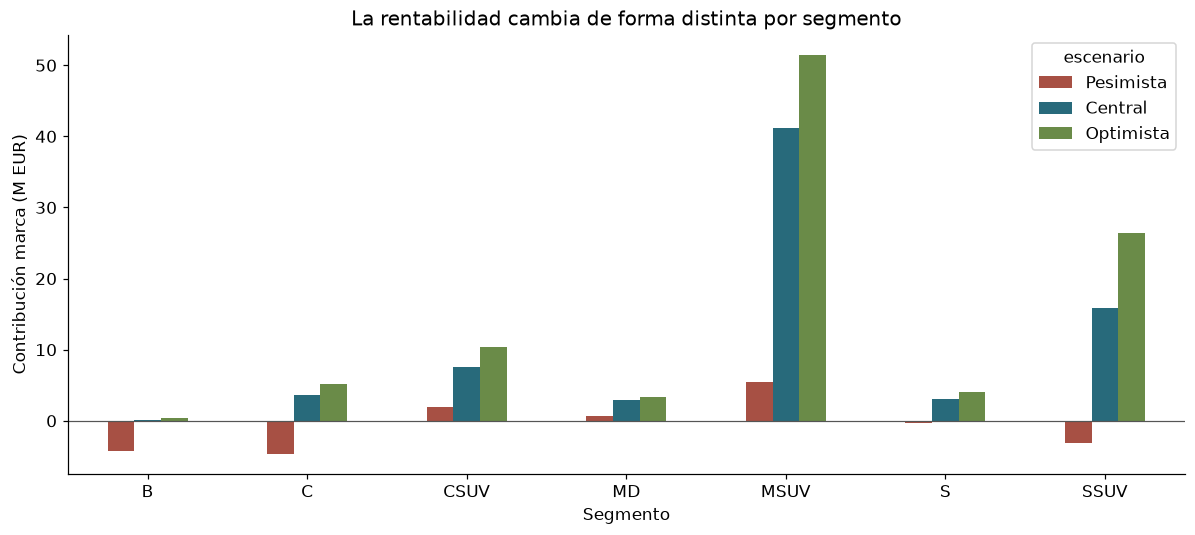

In [7]:
orden=['Pesimista','Central','Optimista']
z=t5.query('segmento != "TOTAL"').pivot(index='segmento',columns='escenario',values='contribucion_marca_eur').reindex(columns=orden)
ax=(z/1e6).plot.bar(figsize=(11,5),color=['#A75044','#286A7B','#6A8B48'])
ax.axhline(0,color='#555555',lw=.8); ax.set_ylabel('Contribución marca (M EUR)'); ax.set_xlabel('Segmento')
ax.set_title('La rentabilidad cambia de forma distinta por segmento'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(salida/'contribucion_segmentos.png',dpi=180); plt.show()

### 6. Comprobaciones y tabla 5

La identidad económica se verifica en todas las combinaciones réplica–mes–segmento. El coste de stock se corta a 180 días y los efectos de caja no entran en la contribución de marca. La clasificación de venta inicial/nueva respeta FIFO.

Las cifras son estimaciones por segmento con precios medios y VM histórico. No conocemos valoración contable detallada de cada coche, gastos fijos, disponibilidad real de transfers o cuánto VM necesitarían los códigos nuevos.

In [8]:
out, _ = cargar_trayectorias()
np.testing.assert_allclose(economicos['contribucion_marca_eur'],economicos['beneficio_bruto_eur']-economicos['vm_eur']-economicos['coste_stock_marca_eur']-economicos['coste_transfers_eur']-economicos['arancel_adicional_eur']-economicos['prima_co2_eur']+economicos['ahorro_cambio_eur'])
np.testing.assert_array_equal(out['ventas'],economicos['ventas_stock_A012']+economicos['ventas_nuevas_y_transfers'])
a=tablas['resultados_economicos_replicas']
for escenario in ['Pesimista','Central','Optimista']:
    suma=a.query('escenario == @escenario and segmento != "TOTAL"').groupby('replica').contribucion_marca_eur.sum()
    total=a.query('escenario == @escenario and segmento == "TOTAL"').set_index('replica').contribucion_marca_eur
    np.testing.assert_allclose(suma,total)
print('Conciliación correcta en',out['ventas'].size,'combinaciones y en los 3.000 totales anuales.')
display(t5[['escenario','segmento','ventas','fabricado','stock_medio','stock_medio_meses_demanda','stock_mas_90','coste_stock_marca_eur','vm_eur','contribucion_marca_eur']])

Conciliación correcta en 252000 combinaciones y en los 3.000 totales anuales.


,escenario,segmento,ventas,fabricado,stock_medio,stock_medio_meses_demanda,stock_mas_90,coste_stock_marca_eur,vm_eur,contribucion_marca_eur
0,Central,B,1554.522,1545.666,166.765083,1.250717,0.050,120070.86,2.669522e+06,7.383635e+04
1,Central,C,3577.858,2536.848,777.771583,2.654019,4.710,541383.09,8.996869e+06,3.575810e+06
2,Central,CSUV,2299.744,1078.794,997.488542,6.013942,154.931,570013.32,6.018646e+06,7.601009e+06
3,Central,MD,736.896,775.384,84.995542,1.383889,0.250,57352.05,2.637941e+06,2.856122e+06
4,Central,MSUV,7119.897,7332.016,792.676208,1.337795,0.000,569676.87,1.354520e+07,4.114965e+07
5,Central,S,652.926,593.374,135.967875,2.622605,26.269,97236.42,1.279395e+06,3.032438e+06
6,Central,SSUV,5787.509,5972.020,540.469208,1.081816,0.000,389137.83,1.143721e+07,1.589109e+07
7,Central,TOTAL,21729.352,19834.102,3496.134042,1.893816,186.210,2344870.44,4.658478e+07,7.417995e+07
8,Optimista,B,1815.871,1896.785,153.478125,0.940598,0.000,110504.25,3.117872e+06,3.509806e+05
9,Optimista,C,4260.011,3353.356,727.747667,2.062441,3.034,512476.80,1.048700e+07,5.229279e+06


In [9]:
tot=t5.query('segmento == "TOTAL"').set_index('escenario')
texto='### Conclusiones económicas\n\n'+ '\n'.join(f'- {e}: contribución **{fila.contribucion_marca_eur/1e6:.2f} M EUR**, VM {fila.vm_eur/1e6:.2f} M EUR y permanencia {fila.coste_stock_marca_eur/1e6:.2f} M EUR.' for e,fila in tot.iterrows())
texto+='\n\nLa pérdida pesimista exige revisar CO2 y segmentos de contribución negativa. Los costes de oportunidad y la caja de la red se muestran aparte. CSUV viejo usa una imputación explícita. La previsión sigue siendo provisional. Continúa en [Sensibilidad y recomendaciones](04_costes_y_politicas.ipynb#politicas).'
(salida/'conclusiones.md').write_text(texto+'\n'); display(Markdown(texto))

### Conclusiones económicas

- Central: contribución **74.18 M EUR**, VM 46.58 M EUR y permanencia 2.34 M EUR.
- Optimista: contribución **101.29 M EUR**, VM 59.71 M EUR y permanencia 2.22 M EUR.
- Pesimista: contribución **-4.08 M EUR**, VM 41.72 M EUR y permanencia 2.31 M EUR.

La pérdida pesimista exige revisar CO2 y segmentos de contribución negativa. Los costes de oportunidad y la caja de la red se muestran aparte. CSUV viejo usa una imputación explícita. La previsión sigue siendo provisional. Continúa en [Sensibilidad y recomendaciones](04_costes_y_politicas.ipynb#politicas).

<a id="politicas"></a>

## B Comparación de políticas

**Objetivo:** comparar decisiones de stock y transfers con euros y servicio, y separar esas decisiones de las hipótesis que necesitan datos nuevos. El [Costes](04_costes_y_politicas.ipynb#costes) valoró el plan base; aquí lo contrastamos con alternativas sin alterar los notebooks anteriores.

Usamos las mismas 1.000 demandas de cada historia en todas las variantes. La capacidad física nominal permanece fija. Es una comparación de alternativas ensayadas, no una búsqueda exhaustiva ni un óptimo probado.

### 1. Qué cambia y qué permanece común

Compararemos revisión activa/inactiva, cobertura de transfers y multiplicadores de seguridad. Añadimos dos combinaciones explícitas de seguridad y transfer completo.

Pipeline ±25% y edades iniciales son **incertidumbres**, no acciones elegibles. «Pedidos registrados» supone información de pedidos durante faltas que los CSV no contienen. No se permite elegir una demanda futura favorable ni diseñar un plan conociendo el escenario que finalmente ocurrirá.

La política modifica las ventas y por tanto la revisión posterior. Cada réplica responde únicamente a su pasado. Fabricación y llegada siguen separadas tres meses.

In [10]:
from src.sensibilidad import ejecutar_sensibilidad, VARIANTES
salida=RESULTADOS/'08_sensibilidad_recomendaciones'
tablas=ejecutar_sensibilidad()
display(pd.DataFrame([{'variante':n, 'cambios':json.dumps(c,ensure_ascii=False)} for n,c in VARIANTES]))

,variante,cambios
0,Base,{}
1,Sin revisión,"{""revision_activa"": false}"
2,Pedidos registrados,"{""observacion_revision"": ""pedidos""}"
3,Sin transfers,"{""fraccion_transfer_deficit"": 0}"
4,Transfer de todo el déficit rentable,"{""fraccion_transfer_deficit"": 1}"
5,Pipeline -25%,"{""pipeline_multiplicador"": 0.75}"
6,Pipeline +25%,"{""pipeline_multiplicador"": 1.25}"
7,Seguridad mitad,"{""multiplicador_seguridad"": 0.5}"
8,Seguridad +50%,"{""multiplicador_seguridad"": 1.5}"
9,Edades iniciales jóvenes,"{""edades_iniciales"": ""jovenes""}"


In [11]:
comparacion=tablas['comparacion_politicas']
campos=['variante','escenario','ventas','ventas_perdidas','servicio_unidades_pct','stock_medio','contribucion_marca_eur','contribucion_p05_eur']
display(comparacion.query('segmento == "TOTAL"')[campos])

,variante,escenario,ventas,ventas_perdidas,servicio_unidades_pct,stock_medio,contribucion_marca_eur,contribucion_p05_eur
7,Base,Central,21729.352,529.720,97.617201,3496.134042,7.417995e+07,6.565930e+07
15,Base,Optimista,28282.078,1707.465,94.315135,3204.848042,1.012852e+08,9.064339e+07
23,Base,Pesimista,19320.828,1024.035,94.966709,3517.506583,-4.080989e+06,-5.943919e+06
31,Sin revisión,Central,21690.379,568.693,97.484101,3716.363875,7.371642e+07,6.557530e+07
39,Sin revisión,Optimista,26296.187,3693.356,87.761020,2626.618000,9.262125e+07,8.641920e+07
47,Sin revisión,Pesimista,19689.782,655.081,96.839290,4337.244250,-4.918586e+06,-6.926920e+06
55,Pedidos registrados,Central,21765.437,493.635,97.779618,3597.658167,7.423143e+07,6.567943e+07
63,Pedidos registrados,Optimista,28584.010,1405.533,95.320208,3348.521042,1.023497e+08,9.145319e+07
71,Pedidos registrados,Pesimista,19467.062,877.801,95.683956,3686.991750,-4.257421e+06,-6.131338e+06
79,Sin transfers,Central,21112.077,1146.995,94.841232,3393.411042,7.262560e+07,6.373239e+07


### 2. Dos objetivos que pueden entrar en conflicto

Un servicio mayor evita faltas, pero mantener más stock tiene un coste. Además, si CO₂ y arancel dejan una venta con margen negativo, servirla puede empeorar la contribución. No basta con ordenar políticas por ventas o por stock.

El gráfico muestra stock medio frente a contribución, separado por escenario. Cada punto es una media de 1.000 réplicas. Las líneas entre escenarios no serían una evolución temporal: son historias alternativas.

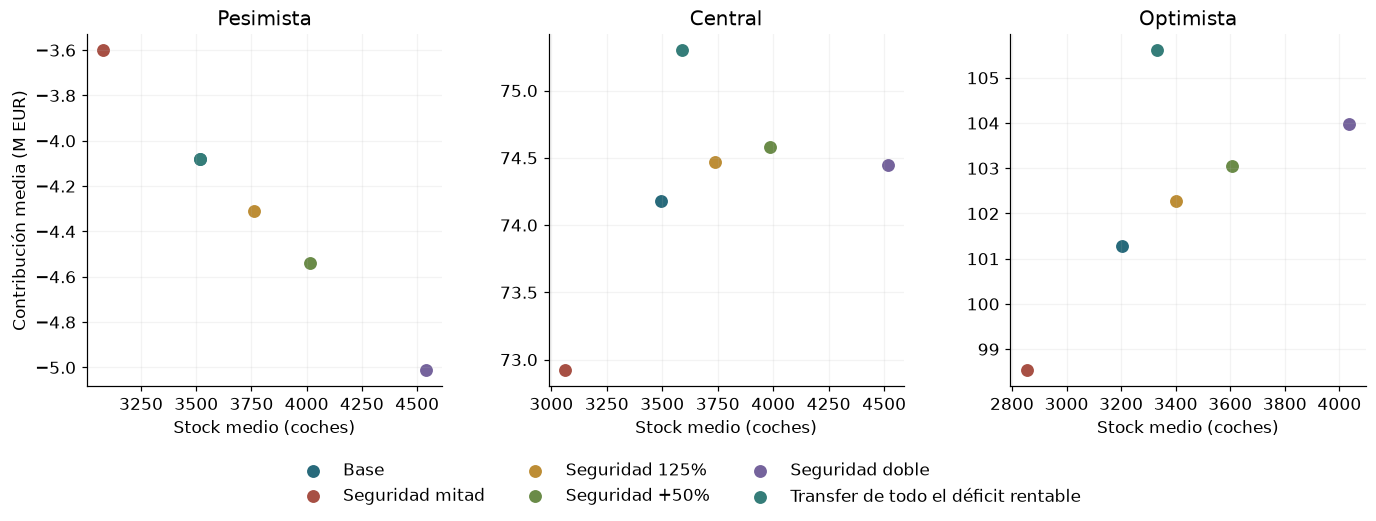

In [12]:
seleccion=['Base','Seguridad mitad','Seguridad 125%','Seguridad +50%','Seguridad doble','Transfer de todo el déficit rentable']
fig,axes=plt.subplots(1,3,figsize=(15,5),sharey=False)
colores=['#286A7B','#A75044','#BD8D35','#6A8B48','#75639C','#357D79']
for ax,escenario in zip(axes,['Pesimista','Central','Optimista']):
    for nombre,color in zip(seleccion,colores):
        fila=comparacion.query('segmento == "TOTAL" and escenario == @escenario and variante == @nombre').iloc[0]
        ax.scatter(fila.stock_medio,fila.contribucion_marca_eur/1e6,color=color,s=55,label=nombre)
    ax.set_title(escenario); ax.set_xlabel('Stock medio (coches)'); ax.grid(alpha=.15)
axes[0].set_ylabel('Contribución media (M EUR)')
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=3,frameon=False)
fig.subplots_adjust(bottom=.24,wspace=.30); fig.savefig(salida/'stock_y_contribucion.png',dpi=180); plt.show()

### 3. Comparaciones pareadas

Para una réplica r calculamos `resultado_alternativa[r] − resultado_base[r]`. Después resumimos esas diferencias. Así eliminamos parte del ruido común de demanda.

Restar P05 de dos políticas no equivale a calcular P05 de sus diferencias. El error Monte Carlo de la diferencia sigue sin medir el error de modelo. Tampoco usamos estas réplicas como una prueba independiente después de seleccionar la política: la clasificación es exploratoria.

In [13]:
delta=tablas['diferencias_pareadas']
display(delta.query('segmento == "TOTAL" and metrica == "contribucion_marca_eur"')[['variante','escenario','delta_media','delta_p05','delta_p95','error_montecarlo_delta_media']])

,variante,escenario,delta_media,delta_p05,delta_p95,error_montecarlo_delta_media
28,Base,Central,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
60,Base,Optimista,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
92,Base,Pesimista,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
124,Sin revisión,Central,-4.635284e+05,-3.670083e+06,1.882039e+06,53258.473487
156,Sin revisión,Optimista,-8.663921e+06,-1.502873e+07,-3.200488e+06,112118.653969
188,Sin revisión,Pesimista,-8.375970e+05,-1.805420e+06,1.247989e+04,17389.498553
220,Pedidos registrados,Central,5.147585e+04,-1.095138e+05,3.770194e+05,5088.137305
252,Pedidos registrados,Optimista,1.064523e+06,4.297387e+05,1.703714e+06,12133.094657
284,Pedidos registrados,Pesimista,-1.764316e+05,-3.861839e+05,-1.963751e+03,3569.869472
316,Sin transfers,Central,-1.554352e+06,-2.836977e+06,-5.884050e+05,21580.013291


### 4. Un criterio de decisión explícito

Sin probabilidades de escenarios, probamos **maximizar el peor margen medio** entre las tres historias. Solo entran políticas operativas; excluimos pipeline, edades y pedidos registrados.

Como alternativa de preferencia del comité, exigimos **servicio medio ≥95% en cada historia**. Es un filtro de análisis que elegimos aquí, no una obligación del enunciado ni una garantía de atender el 95% en cada réplica. Mostramos también el peor P05 del margen para que la media no oculte el riesgo.

La mejor política según margen puede incumplir servicio. Si ambas metas son necesarias, el comité debe aceptar el coste de cumplirlas o revisar costes/comercialización. No cambiaremos automáticamente el plan base con la política seleccionada en esta muestra.

In [14]:
ranking=tablas['ranking_robusto']
display(ranking)
viables=ranking[ranking.cumple_servicio_medio_95_tres_escenarios]
print('Mejor peor margen entre políticas ensayadas:',ranking.iloc[0].variante)
print('Con filtro de servicio medio 95%:',viables.iloc[0].variante if len(viables) else 'Ninguna')

,variante,peor_margen_medio_eur,peor_p05_margen_eur,peor_servicio_medio_pct,mayor_stock_medio,cumple_servicio_medio_95_tres_escenarios
6,Seguridad mitad,-3.601281e+06,-5.354740e+06,90.750211,3077.783000,False
7,Seguridad mitad y transfer completo,-3.601281e+06,-5.354740e+06,90.750211,3166.454500,False
4,Seguridad 75%,-3.850015e+06,-5.653653e+06,93.223906,3286.173000,False
0,Base,-4.080989e+06,-5.943919e+06,94.315135,3517.506583,False
9,Sin transfers,-4.080989e+06,-5.943919e+06,84.235333,3517.506583,False
10,Transfer de todo el déficit rentable,-4.080989e+06,-5.943919e+06,94.966709,3589.303667,False
3,Seguridad 125%,-4.311994e+06,-6.130868e+06,95.161227,3761.163875,True
1,Seguridad +50%,-4.540146e+06,-6.402692e+06,95.852327,4012.830417,True
2,Seguridad +50% y transfer completo,-4.540146e+06,-6.402692e+06,96.905774,4072.186750,True
8,Sin revisión,-4.918586e+06,-6.926920e+06,87.761020,4337.244250,False


Mejor peor margen entre políticas ensayadas: Seguridad mitad
Con filtro de servicio medio 95%: Seguridad 125%


### 5. Hipótesis económicas y datos pendientes

Variamos VM de CSUV viejo, coste diario de permanencia y base de arancel/cambio. También mostramos qué pasaría con las mismas ventas si la matriz no cargara CO₂.

Estas variantes mantienen las trayectorias físicas del bloque de simulación para aislar la valoración. **No** representan la nueva política que resultaría si la dirección reaccionara a esos precios: los transfers y pedidos no se recalculan. La exención de CO₂ solo afecta al pesimista actual.

Confirmar pipeline y capacidad puede ser más útil que afinar decimales de una política sustentada en proxies.

,hipotesis,escenario,contribucion_marca_eur,coste_stock_marca_eur,vm_eur,prima_co2_eur
7,VM CSUV viejo sin incremento,Central,7.455978e+07,2344870.440,4.620495e+07,0.000000e+00
15,VM CSUV viejo sin incremento,Optimista,1.015613e+08,2216388.840,5.943835e+07,0.000000e+00
23,VM CSUV viejo sin incremento,Pesimista,-3.666343e+06,2308251.870,4.131024e+07,5.845235e+07
31,VM CSUV viejo +50%,Central,7.361022e+07,2344870.440,4.715452e+07,0.000000e+00
39,VM CSUV viejo +50%,Optimista,1.008710e+08,2216388.840,6.012868e+07,0.000000e+00
47,VM CSUV viejo +50%,Pesimista,-4.702959e+06,2308251.870,4.234685e+07,5.845235e+07
55,Permanencia marca 1 EUR/día,Central,7.535239e+07,1172435.220,4.658478e+07,0.000000e+00
63,Permanencia marca 1 EUR/día,Optimista,1.023934e+08,1108194.420,5.971448e+07,0.000000e+00
71,Permanencia marca 1 EUR/día,Pesimista,-2.926863e+06,1154125.935,4.172488e+07,5.845235e+07
79,Permanencia marca 3 EUR/día,Central,7.300752e+07,3517305.660,4.658478e+07,0.000000e+00


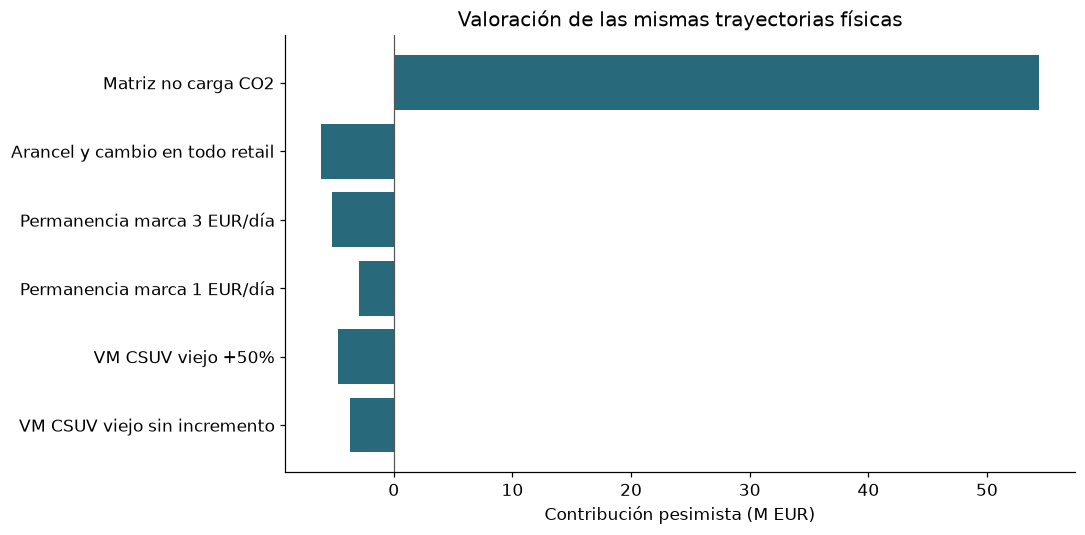

In [15]:
eco=tablas['sensibilidad_costes']
display(eco.query('segmento == "TOTAL"')[['hipotesis','escenario','contribucion_marca_eur','coste_stock_marca_eur','vm_eur','prima_co2_eur']])
z=eco.query('segmento == "TOTAL" and escenario == "Pesimista"').copy()
fig,ax=plt.subplots(figsize=(10,5)); ax.barh(z.hipotesis,z.contribucion_marca_eur/1e6,color='#286A7B')
ax.axvline(0,color='#555555',lw=.8); ax.set_xlabel('Contribución pesimista (M EUR)')
ax.set_title('Valoración de las mismas trayectorias físicas')
fig.tight_layout(); fig.savefig(salida/'sensibilidad_costes.png',dpi=180); plt.show()

### 6. Recomendaciones por segmento

MSUV y SSUV concentran contribución central. Necesitan disponibilidad, especialmente en meses fuertes y en la llegada afectada por la parada. C y CSUV comienzan con exceso: primero hay que vender el stock existente y confirmar la cuota de CSUV. MD y S requieren revisión del pronóstico, aunque su margen unitario sea atractivo.

B tiene contribución central muy reducida. Eso no demuestra que cada venta de B pierda dinero: el VM fresco y el stock ya existente son distintos del promedio. Hay que evitar empujarlo por volumen sin verificar margen incremental. En pesimista revisamos los segmentos con contribución negativa antes de ampliar campañas o stock.

El seguimiento mensual debe registrar demanda no atendida y pedidos, además de ventas. Cuando hay falta de stock, las ventas censuran la demanda y pueden inducir una revisión excesivamente baja.

In [16]:
base=comparacion.query('variante == "Base" and segmento != "TOTAL"')
z=base.pivot(index='segmento',columns='escenario',values='contribucion_marca_eur')/1e6
display(z)
seguimiento=pd.DataFrame([
 {'señal':'Ventas/pedidos frente a previsión','acción':'Revisar pronóstico y pedido para t+3; verificar faltas antes de interpretar una caída.'},
 {'señal':'Stock y edad por segmento','acción':'Vender primero cohortes antiguas; controlar C y CSUV y confirmar VM viejo.'},
 {'señal':'Margen incremental después de CO2/arancel','acción':'Revisar campañas, seguridad y transfers si una operación es deficitaria.'},
 {'señal':'Pipeline y producción confirmada','acción':'Actualizar llegadas comprometidas sin cambiar retroactivamente barcos en tránsito.'},
 {'señal':'Vencimientos de crédito de la red','acción':'Coordinar caja y venta del stock viejo; separar principal e intereses.'}])
seguimiento.to_csv(salida/'seguimiento_mensual.csv',index=False); display(seguimiento)

escenario,Central,Optimista,Pesimista
segmento,,,
B,0.073836,0.350981,-4.192450
C,3.575810,5.229279,-4.622992
CSUV,7.601009,10.340928,1.944884
MD,2.856122,3.404008,0.693090
MSUV,41.149648,51.506667,5.498211
S,3.032438,4.004599,-0.296337
SSUV,15.891089,26.448705,-3.105394


,señal,acción
0,Ventas/pedidos frente a previsión,Revisar pronóstico y pedido para t+3; verifica...
1,Stock y edad por segmento,Vender primero cohortes antiguas; controlar C ...
2,Margen incremental después de CO2/arancel,"Revisar campañas, seguridad y transfers si una..."
3,Pipeline y producción confirmada,Actualizar llegadas comprometidas sin cambiar ...
4,Vencimientos de crédito de la red,Coordinar caja y venta del stock viejo; separa...


In [17]:
texto=f"### Conclusiones de las políticas\n\n- Mejor peor margen medio entre alternativas: **{ranking.iloc[0].variante}**. No alcanza el servicio medio del 95% en todas las historias.\n- Con ese filtro de servicio, la mejor alternativa ensayada es **{viables.iloc[0].variante if len(viables) else 'ninguna'}**.\n- CO₂ domina una parte importante del deterioro pesimista. Conviene confirmar su imputación antes de aprobar crecimiento.\n- Transfers rentables, información de pedidos y seguridad cambian servicio y margen. Su disponibilidad y observabilidad deben confirmarse.\n\nConservamos el plan base para una entrega comparable. La política es una primera propuesta condicionada a mejorar la previsión y confirmar datos operativos. Las tablas finales se exportan en la última sección de este notebook."
(salida/'conclusiones.md').write_text(texto+'\n'); display(Markdown(texto))

### Conclusiones de las políticas

- Mejor peor margen medio entre alternativas: **Seguridad mitad**. No alcanza el servicio medio del 95% en todas las historias.
- Con ese filtro de servicio, la mejor alternativa ensayada es **Seguridad 125%**.
- CO₂ domina una parte importante del deterioro pesimista. Conviene confirmar su imputación antes de aprobar crecimiento.
- Transfers rentables, información de pedidos y seguridad cambian servicio y margen. Su disponibilidad y observabilidad deben confirmarse.

Conservamos el plan base para una entrega comparable. La política es una primera propuesta condicionada a mejorar la previsión y confirmar datos operativos. Las tablas finales se exportan en la última sección de este notebook.

## C Tablas que respaldan los documentos

Exportamos la fabricación mensual y la tabla 5 para el total y los siete segmentos. Incluyen CVP y contribución como magnitudes distintas. Los PDF y Word se revisan por separado y no se sobrescriben al ejecutar los cálculos.

In [18]:
from src.tablas_entrega import exportar_tablas
produccion_final, tabla_final = exportar_tablas()
display(produccion_final)
display(tabla_final.query('segmento == "TOTAL"').T)

segmento,B,C,MD,SSUV,CSUV,MSUV,S,TOTAL
mes,,,,,,,,
1,136,0,70,267,0,582,42,1097
2,134,0,69,300,0,620,50,1173
3,147,0,73,516,0,642,62,1440
4,149,248,75,544,0,717,60,1793
5,127,283,63,485,0,497,61,1516
6,132,299,67,528,0,552,55,1633
7,136,300,67,559,73,627,64,1826
8,135,299,66,562,197,643,55,1957
9,138,304,67,581,208,693,53,2044


,7,15,23
escenario,Central,Optimista,Pesimista
segmento,TOTAL,TOTAL,TOTAL
ventas,21729.352,28282.078,19320.828
fabricado,19834.102,27067.452,17385.961
stock_medio,3496.134042,3204.848042,3517.506583
stock_medio_meses_demanda,1.893816,1.28808,2.084964
stock_final,1647.526,1350.232,1507.076
stock_mas_90,186.21,70.992,270.52
coste_stock_marca_eur,2344870.44,2216388.84,2308251.87
ventas_perdidas,529.72,1707.465,1024.035
